Enter population size (even number): 20
Enter number of generations: 50
Enter mutation rate (0 to 1): 0.2
Enter crossover rate (0 to 1): 0.8

Best path found:
[[ 0.          0.        ]
 [ 2.45781779  0.32100131]
 [ 7.08007574  2.94719508]
 [ 8.1352849   4.30377986]
 [ 9.78446637  8.14799424]
 [10.         10.        ]]
Total path length: 15.56
Best fitness: 0.06426


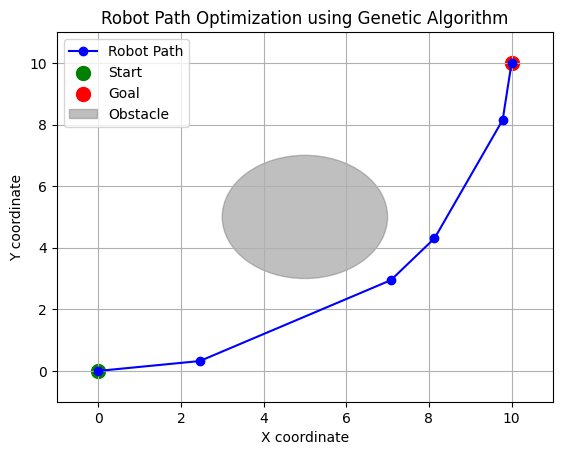

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt

# 1. Problem setup
START = np.array([0.0, 0.0])
GOAL = np.array([10.0, 10.0])
OBSTACLE = np.array([5.0, 5.0])
RADIUS = 2.0
NUM_WAYPOINTS = 4

# 2. Get hyperparameters from user
POP_SIZE = int(input("Enter population size (even number): "))
GENERATIONS = int(input("Enter number of generations: "))
MUTATION_RATE = float(input("Enter mutation rate (0 to 1): "))
CROSSOVER_RATE = float(input("Enter crossover rate (0 to 1): "))


# 3. Initialize population
def initialize_population():
    return np.random.uniform(
        0, 10, (POP_SIZE, NUM_WAYPOINTS, 2)
    )


# 4. Fitness evaluation
def fitness(path):
    points = np.vstack([START, path, GOAL])
    length = np.sum(
        np.linalg.norm(np.diff(points, axis=0), axis=1)
    )

    collision = False

    for i in range(len(points) - 1):
        for t in np.linspace(0, 1, 20):
            p = points[i] + t * (points[i + 1] - points[i])

            if np.linalg.norm(p - OBSTACLE) <= RADIUS:
                collision = True
                break
        if collision:
            break

    if collision:
        return 1 / (length + 1000)

    return 1 / length


# 5. Selection
def selection(population, scores):
    probabilities = scores / scores.sum()
    indices = np.random.choice(
        len(population), size=2, p=probabilities
    )
    return population[indices[0]], population[indices[1]]


# 6. Crossover
def crossover(parent1, parent2):
    if random.random() < CROSSOVER_RATE:
        point = random.randint(1, NUM_WAYPOINTS - 1)
        child = np.vstack([
            parent1[:point], parent2[point:]
        ])
    else:
        child = parent1.copy()

    return child


# 7. Mutation
def mutation(path):
    if random.random() < MUTATION_RATE:
        i = random.randint(0, NUM_WAYPOINTS - 1)
        path[i] = np.random.uniform(0, 10, 2)
    return path


# 8. Genetic Algorithm
population = initialize_population()
best_path = None
best_score = -1

for gen in range(GENERATIONS):
    scores = np.array([fitness(path) for path in population])

    idx = np.argmax(scores)

    if scores[idx] > best_score:
        best_score = scores[idx]
        best_path = population[idx].copy()

    # Elitism: preserve the best path
    new_population = [best_path.copy()]

    while len(new_population) < POP_SIZE:
        p1, p2 = selection(population, scores)
        child = crossover(p1, p2)
        child = mutation(child)
        new_population.append(child)

    population = np.array(new_population)

# 9. Display result
points = np.vstack([START, best_path, GOAL])
length = np.sum(
    np.linalg.norm(np.diff(points, axis=0), axis=1)
)

print("\nBest path found:")
print(points)
print("Total path length:", round(length, 2))
print("Best fitness:", round(best_score, 5))

# 10. Plot path
plt.plot(points[:, 0], points[:, 1], 'bo-', label="Robot Path")
plt.scatter(*START, color='green', s=100, label="Start")
plt.scatter(*GOAL, color='red', s=100, label="Goal")

circle = plt.Circle(
    OBSTACLE, RADIUS, color='gray', alpha=0.5,
    label="Obstacle"
)
plt.gca().add_patch(circle)

plt.xlim(-1, 11)
plt.ylim(-1, 11)
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("Robot Path Optimization using Genetic Algorithm")
plt.legend()
plt.grid()
plt.show()
